In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd
normal_equations = __import__('0-normal_equations').normal_equations
mse_cost = __import__('1-cost_gradient').mse_cost
batch_gradient_descent = __import__('2-batch_gradient_descent').batch_gradient_descent
stochastic_gradient_descent = __import__('3-stochastic_gradient_descent').stochastic_gradient_descent
standardize = __import__('4-feature_scaling').standardize
add_intercept = __import__('4-feature_scaling').add_intercept


In [2]:
rng = np.random.default_rng(0)
m = 1000
scales = np.array([1, 10, 100])
X_raw = rng.normal(size=(m, 3)) * scales
X_u = add_intercept(X_raw)
intercept = 10
w_std1 = 4
w_std10 = 2
w_std100 = 0.5
theta_true = np.array([intercept, w_std1, w_std10, w_std100])
noise_level = 1.5
noise = rng.normal(size=m) * noise_level
y = X_u @ theta_true + noise
print("y shape:", y.shape)
X_raw_norm, mu, sigma = standardize(X_raw)
X_s = add_intercept(X_raw_norm)
print("First column:", X_u[:, 0])
print("X_s shape:", X_s.shape)   
print("X_s first column (intercept):", X_s[:5, 0])           # Expected: [1., 1., 1., 1., 1.]
print("X_s feature standard deviations:", X_s[:, 1:].std(axis=0))
print("Shape:", X_u.shape)       # Expected: (1000, 4)
print("First column:", X_u[:, 0])
print("raw feature stds:", X_raw.std(axis=0))

y shape: (1000,)
First column: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1

1.0176558105731919 1.965301017515446
0.01 210.20682053932958
0.1 1.1367590439533204
0.9 1.1367575400918186
2.5 1.1327482355673995e+40


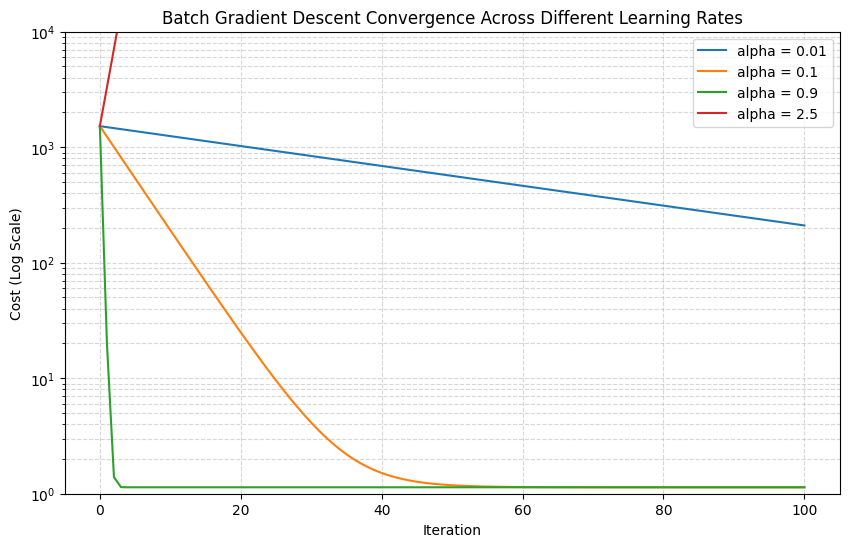

In [3]:
lam = np.linalg.eigvalsh(X_s.T @ X_s / m).max()
print(lam, 2 / lam)
alphas = [0.01, 0.1, 0.9, 2.5]
plt.figure(figsize=(10, 6))
for a in alphas:
    with np.errstate(all="ignore"):
        theta, costs = batch_gradient_descent(X_s, y, alpha=a, iterations=100)
    plt.plot(costs, label=f"alpha = {a}")
    
    print(a, costs[-1])
plt.ylim(1, 1e4)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Cost (Log Scale)")
plt.title("Batch Gradient Descent Convergence Across Different Learning Rates")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

Alphas 0.01, 0.1 and 0.9 all converge, and 0.9 is the fastest (0.01 has not reached the floor after 100 iterations). The rate 2.5 diverges because it is larger than 2/λ_max ≈ 1.97, so each step overshoots by more than it corrects. The converged runs flatten at about 1.1, the noise floor set by the noise in y, not at 0.

In [4]:
lam_u_all = np.linalg.eigvalsh(X_u.T @ X_u / m)
print(lam_u_all)
print(lam_u_all.max())
print(2 / lam_u_all.max())
print(lam_u_all.max() / lam_u_all.min())

[8.93696779e-01 1.09636480e+00 9.32414066e+01 1.04376465e+04]
10437.646530362226
0.0001916140764282609
11679.181095466569


In [5]:
def is_stable(a):
    with np.errstate(all="ignore"):
      theta, costs = batch_gradient_descent(X_u, y, alpha=a, iterations=300)
      tol = 1e-9 * costs[0]
      return bool(np.all(np.isfinite(costs)) and np.all(np.diff(costs) <= tol))
print(is_stable(1e-7))
print(is_stable(1e-2))

True
False


In [6]:
lo = 1e-7
hi = 1e-2
for _ in range(40):
    mid = np.sqrt(lo * hi)
    if is_stable(mid):
        lo = mid
    else:
        hi = mid
print(2 / lam_u_all.max())
print("largest stable alpha (bisection):", lo)
print("2 / lambda_max                  :", 2 / lam_u_all.max())

0.0001916140764282609
largest stable alpha (bisection): 0.00019161473279717166
2 / lambda_max                  : 0.0001916140764282609


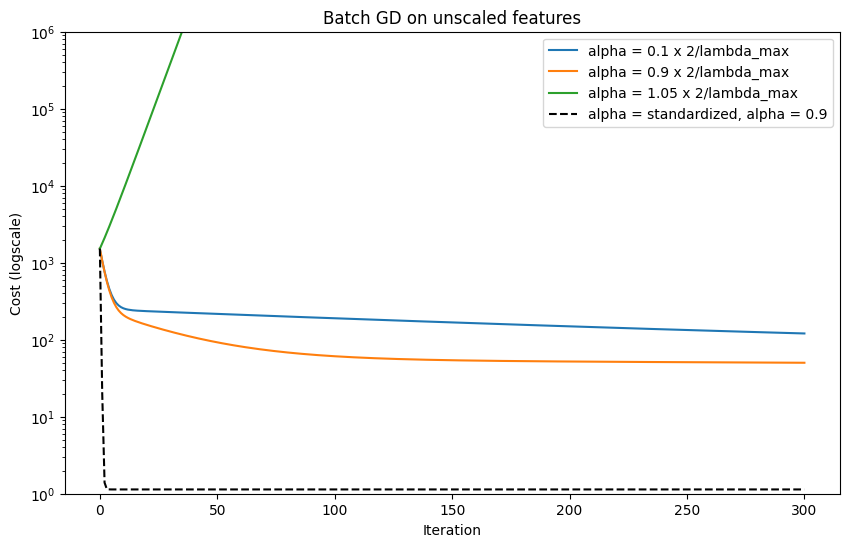

In [7]:
lim = 2 / lam_u_all.max()
plt.figure(figsize=(10, 6))
for frac in [0.1, 0.9, 1.05]:
    a = frac * lim
    with np.errstate(all="ignore"):
        theta, costs = batch_gradient_descent(X_u, y, alpha=a, iterations=300)
    plt.plot(costs, label=f"alpha = {frac} x 2/lambda_max")
theta, costs = batch_gradient_descent(X_s, y, alpha=0.9, iterations=300)
plt.plot(costs,  "k--", label=f"alpha = standardized, alpha = 0.9")
plt.yscale("log")
plt.ylim(1, 1e6)
plt.xlabel("Iteration")
plt.ylabel("Cost (logscale)")
plt.title("Batch GD on unscaled features")
plt.legend()
plt.show()

The largest stable alpha matches 2 / lambda_max (about 1.9e-4), found by both the bisection and the formula. It is so small because the std-100 feature makes lambda_max about 1e4.Even stable runs are slow, because the eigenvalues span four orders of magnitude (condition number about 1.2e4), which is what standardization fixes.

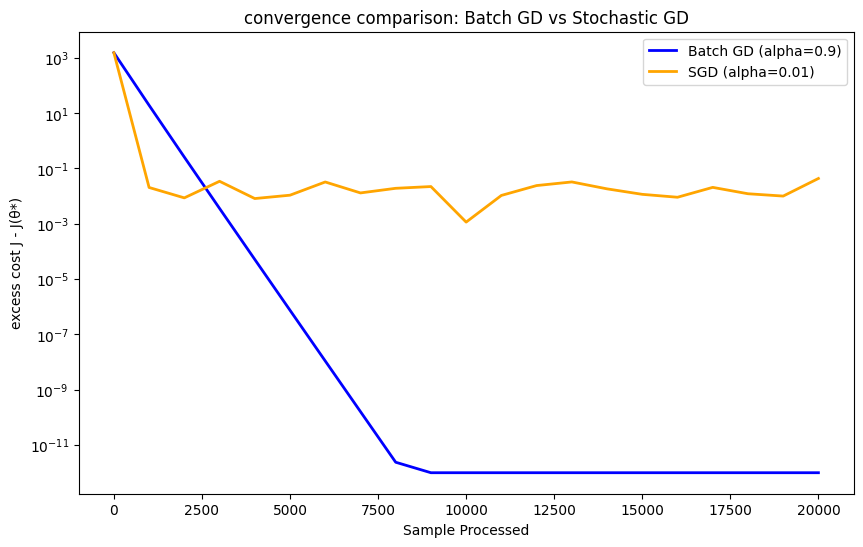

In [8]:
theta_ne = normal_equations(X_s, y)
J_star = mse_cost(X_s, y, theta_ne)
epochs = 20
theta_b, c_b = batch_gradient_descent(X_s, y, alpha=0.9, iterations=epochs)
theta_s, c_s = stochastic_gradient_descent(X_s, y, alpha=0.01, epochs=epochs, seed=0)
samples = np.arange(epochs + 1) * m
plt.figure(figsize=(10, 6))
excess_batch = np.maximum(c_b - J_star, 1e-12)
excess_sgd = np.maximum(c_s - J_star, 1e-12)
plt.plot(samples, excess_batch, label="Batch GD (alpha=0.9)", color="blue", linewidth=2)
plt.plot(samples, excess_sgd, label="SGD (alpha=0.01)", color="orange", linewidth=2)
plt.yscale("log")
plt.xlabel("Sample Processed")
plt.ylabel("excess cost J - J(θ*)")
plt.title("convergence comparison: Batch GD vs Stochastic GD")
plt.legend()
plt.savefig("convergence.png", dpi=150)
plt.show()


SGD wins early because it makes m updates per pass while batch GD makes one, then batch GD overtakes it and converges to the optimum, while SGD stays at a noise floor

SGD is ahead after the first epoch, because it makes m updates per pass while batch GD makes one.
Batch GD then overtakes it and keeps falling toward the optimum.
SGD stays at a noise floor of about 1e-2, set by its constant step size

In [15]:
def best_time(f, repeats=5):
    best_t = float('inf')
    result = None
    for _ in range(repeats):
        start = time.perf_counter()
        result = f()
        elapsed = time.perf_counter() - start
        if elapsed < best_t:
            best_t = elapsed
    return result, best_t


print(best_time(lambda: sum(range(1000))))
# Using lambdas to defer execution and unpacking element [0] for gradient descent weights
theta_ne, t_ne = best_time(lambda: normal_equations(X_s, y))
theta_bgd, t_bgd = best_time(lambda: batch_gradient_descent(X_s, y, alpha=0.9, iterations=100)[0])
theta_sgd, t_sgd = best_time(lambda: stochastic_gradient_descent(X_s, y, alpha=0.01, epochs=20, seed=0)[0])
methods = ["Normal Equations", "Batch GD", "SGD"]
all_thetas = np.vstack([theta_ne, theta_bgd, theta_sgd])
times_ms = [t_ne * 1000, t_bgd * 1000, t_sgd * 1000]
df = pd.DataFrame(
    all_thetas, 
    columns=["theta_0 (Intercept)", "theta_1", "theta_2", "theta_3"], 
    index=methods
)
# Calculate maximum absolute difference against the exact analytical normal equation parameters
df["Max Diff from NE"] = np.abs(all_thetas - theta_ne).max(axis=1)
df["Time (ms)"] = times_ms

# Display the table (Jupyter automatically renders this last line beautifully)
df.round(4)


(499500, 6.899999971210491e-05)


,theta_0 (Intercept),theta_1,theta_2,theta_3,Max Diff from NE,Time (ms)
Normal Equations,8.7848,3.8878,19.3888,51.1162,0.0000,0.1995
Batch GD,8.7848,3.8878,19.3888,51.1162,0.0000,11.5040
SGD,8.8513,3.9446,19.1306,51.0025,0.2582,1302.1667
